# TRABAJO HERRAMIENTAS BASICAS PARA EL ANALISIS DE DATOS


## 0.PLANTEO DEL CASO Y PREGUNTAS ANALITICAS

**Pregunta Principal:** ¿Cómo evolucionaron las ventas totales y el beneficio operativo de Adidas entre 2020 y 2021 a través de sus distribuidores, canales de venta y líneas de productos en Estados Unidos?

**Subpreguntas:**

* KPI 1: ¿Cuál fue la tasa de crecimiento de las ventas entre 2020 y 2021? (Evolución temporal)

* KPI 2: ¿Qué método de venta (Online, Outlet, In-store) genera el mayor volumen de facturación frente al mayor margen operativo? (Eficiencia por canal)

* KPI 3: ¿Qué distribuidores (retailers) y categorías de productos representan la mayor participación en los ingresos? (Concentración Comercial)

## 1.IMPORTACION DE DATOS

### A. IMPORTAR LIBRERIAS

In [1]:
import pandas as pd

### B. IMPORTAR DATOS

In [2]:
adidasdata=pd.read_csv("/content/drive/MyDrive/CURSO UTN/Adidas US Sales.csv")

In [3]:
adidasdata

,sales_id,retailer,retailer_id,invoice_date,region,state,city,product,price_per_unit,units_sold,total_sales,operating_profit,sales_method
0,1,Foot Locker,1185732,2021-11-06,Southeast,South Carolina,Charleston,Men's Street Footwear,50,278,13900,792,Online
1,2,Foot Locker,1185732,2020-03-14,Northeast,New York,New York,Men's Apparel,46,278,12788,435,Outlet
2,3,West Gear,1128299,2021-01-19,West,California,San Francisco,Men's Athletic Footwear,47,278,13066,287,Outlet
3,4,Walmart,1128299,2021-06-17,Southeast,Florida,Orlando,Women's Apparel,103,218,22454,1257,Online
4,5,Sports Direct,1197831,2021-09-14,South,Alabama,Birmingham,Women's Street Footwear,36,278,10008,530,Outlet
...,...,...,...,...,...,...,...,...,...,...,...,...,...
9632,9633,Amazon,1185732,2021-11-18,Northeast,Maine,Portland,Men's Apparel,65,150,9750,2438,Outlet
9633,9634,Amazon,1185732,2021-10-22,West,Alaska,Anchorage,Women's Athletic Footwear,65,150,9750,2438,Outlet
9634,9635,Amazon,1185732,2021-10-22,West,Alaska,Anchorage,Men's Apparel,75,150,11250,2813,Outlet
9635,9636,West Gear,1185732,2021-04-10,Midwest,Indiana,Indianapolis,Men's Apparel,65,150,9750,2925,In-store


## 2.EXPLORACION

### A. DICCIONARIO DE COLUMNAS


*   **sales_id:** Un identificador único asignado a cada registro del conjunto de datos.

---

*   **retailer**:Representa a la empresa o persona que vende productos Adidas directamente a los consumidores.


---


*   **retailer_id**: Un identificador único asignado a cada minorista en el conjunto de datos.


---


*   **invoice_date**: La fecha en que se emitió una factura o se realizó una transacción de venta en particular.


---


*   **region**:Se refiere a un área geográfica o distrito específico donde se realizó la transacción de venta.

---


*   **state**: Representa una división administrativa o territorio específico dentro del país donde se realizó la transacción de venta.

---


*   **city**: Se refiere a la zona urbana o municipio donde se realizó la transacción de venta.

---


*   **product**: Representa la clasificación o agrupación de productos Adidas.

---


*   **price_per_unit**: El costo o precio asociado a una sola unidad de un producto. Valores en USD.

---


*   **units_sold**: La cantidad o número de unidades de un producto determinado vendidas durante una transacción de venta específica.

---


*   **total_sales**:Ingresos totales generados por la transacción de venta. Valores en USD.

---


*   **operating_profit**: El beneficio obtenido por el minorista en sus operaciones comerciales habituales. Valores en USD.

---


*   **sales_method**: El método o canal utilizado por el minorista para vender sus productos.





### B. ENTENDIMIENTO DE LOS DATOS

In [4]:
adidasdata.shape

(9637, 13)

In [5]:
adidasdata.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9637 entries, 0 to 9636
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   sales_id          9637 non-null   int64 
 1   retailer          9637 non-null   object
 2   retailer_id       9637 non-null   int64 
 3   invoice_date      9637 non-null   object
 4   region            9637 non-null   object
 5   state             9637 non-null   object
 6   city              9637 non-null   object
 7   product           9637 non-null   object
 8   price_per_unit    9637 non-null   int64 
 9   units_sold        9637 non-null   int64 
 10  total_sales       9637 non-null   int64 
 11  operating_profit  9637 non-null   int64 
 12  sales_method      9637 non-null   object
dtypes: int64(6), object(7)
memory usage: 978.9+ KB


In [6]:
adidasdata.head()

,sales_id,retailer,retailer_id,invoice_date,region,state,city,product,price_per_unit,units_sold,total_sales,operating_profit,sales_method
0,1,Foot Locker,1185732,2021-11-06,Southeast,South Carolina,Charleston,Men's Street Footwear,50,278,13900,792,Online
1,2,Foot Locker,1185732,2020-03-14,Northeast,New York,New York,Men's Apparel,46,278,12788,435,Outlet
2,3,West Gear,1128299,2021-01-19,West,California,San Francisco,Men's Athletic Footwear,47,278,13066,287,Outlet
3,4,Walmart,1128299,2021-06-17,Southeast,Florida,Orlando,Women's Apparel,103,218,22454,1257,Online
4,5,Sports Direct,1197831,2021-09-14,South,Alabama,Birmingham,Women's Street Footwear,36,278,10008,530,Outlet


In [7]:
adidasdata.dtypes

,0
sales_id,int64
retailer,object
retailer_id,int64
invoice_date,object
region,object
state,object
city,object
product,object
price_per_unit,int64
units_sold,int64


### C.LIMPIEZA DE DATOS

In [8]:
# Transformar 'invoice_date' a datetime64
adidasdata['invoice_date'] = pd.to_datetime(adidasdata['invoice_date'])

# Transformar 'retailer_id' a object (texto)
adidasdata['retailer_id'] = adidasdata['retailer_id'].astype(str)

# Verificar los nuevos tipos de datos
print(adidasdata[['invoice_date', 'retailer_id']].dtypes)

invoice_date    datetime64[ns]
retailer_id             object
dtype: object


In [9]:
adidasdata.dtypes

,0
sales_id,int64
retailer,object
retailer_id,object
invoice_date,datetime64[ns]
region,object
state,object
city,object
product,object
price_per_unit,int64
units_sold,int64


In [10]:
adidasdata.duplicated().sum()

np.int64(0)

## 3.IMPORTACIÓN DIRECTA DE DATOS LIMPIOS

Este bloque de código permite cargar el archivo CSV aplicando directamente las transformaciones de tipos de datos que definimos en la etapa de limpieza.

In [11]:
import pandas as pd

def cargar_y_limpiar_adidas(path):
    # 1. Cargar el dataset definiendo 'retailer_id' como string para evitar análisis matemático
    df = pd.read_csv(path, dtype={'retailer_id': str})

    # 2. Convertir la columna de fechas al formato correcto de datetime64
    df['invoice_date'] = pd.to_datetime(df['invoice_date'])

    return df

# Ejemplo de uso:
ruta_archivo = "/content/drive/MyDrive/CURSO UTN/Adidas US Sales.csv"
adidasdata_limpio = cargar_y_limpiar_adidas(ruta_archivo)

# Verificación de la estructura resultante
print(adidasdata_limpio.dtypes)

sales_id                     int64
retailer                    object
retailer_id                 object
invoice_date        datetime64[ns]
region                      object
state                       object
city                        object
product                     object
price_per_unit               int64
units_sold                   int64
total_sales                  int64
operating_profit             int64
sales_method                object
dtype: object


## 4.EXPLORACION ESTADISTICA INICIAL

In [12]:
adidasdata_limpio.describe()

,sales_id,invoice_date,price_per_unit,units_sold,total_sales,operating_profit
count,9637.000000,9637,9637.000000,9637.000000,9637.000000,9637.000000
mean,4819.000000,2021-05-10 16:52:11.929023232,45.218948,256.886064,12451.621355,3440.706029
min,1.000000,2020-01-01 00:00:00,7.000000,6.000000,160.000000,8.000000
25%,2410.000000,2021-02-17 00:00:00,35.000000,106.000000,4068.000000,192.000000
50%,4819.000000,2021-06-04 00:00:00,45.000000,176.000000,7805.000000,437.000000
75%,7228.000000,2021-09-16 00:00:00,55.000000,350.000000,15834.000000,5200.000000
max,9637.000000,2021-12-31 00:00:00,110.000000,1275.000000,82500.000000,39000.000000
std,2782.106606,NaN,14.704520,214.097600,12708.094249,5418.210200


In [13]:
# Frecuencia de distribuidores (KPI 3 - Participación)
print("=== Conteo de Registros por Distribuidor (Retailer) ===")
display(adidasdata_limpio['retailer'].value_counts())

# Frecuencia de métodos de venta (KPI 2 - Eficiencia por canal)
print("\n=== Conteo de Registros por Método de Venta (Sales Method) ===")
display(adidasdata_limpio['sales_method'].value_counts())

# Frecuencia de tipos de producto (KPI 3 - Concentración comercial)
print("\n=== Conteo de Registros por Tipo de Producto (Product) ===")
display(adidasdata_limpio['product'].value_counts())

=== Conteo de Registros por Distribuidor (Retailer) ===


,count
retailer,
Foot Locker,2630
West Gear,2372
Sports Direct,2030
Kohl's,1030
Amazon,949
Walmart,626



=== Conteo de Registros por Método de Venta (Sales Method) ===


,count
sales_method,
Online,4887
Outlet,3010
In-store,1740



=== Conteo de Registros por Tipo de Producto (Product) ===


,count
product,
Men's Street Footwear,1610
Men's Athletic Footwear,1608
Women's Apparel,1607
Women's Street Footwear,1606
Men's Apparel,1605
Women's Athletic Footwear,1601


### E. ANÁLISIS DE CORRELACIÓN
Para profundizar en el entendimiento de las métricas de negocio, calcularemos la matriz de correlación sobre las variables cuantitativas de nuestro dataset (como `price_per_unit`, `units_sold`, `total_sales`, y `operating_profit`). Esto nos permitirá cuantificar la fuerza y dirección de la relación lineal entre ellas.

In [14]:
import pandas as pd

# Seleccionar las columnas numéricas relevantes para el análisis sobre el dataset limpio
columnas_numericas = ['price_per_unit', 'units_sold', 'total_sales', 'operating_profit']
matriz_correlacion = adidasdata_limpio[columnas_numericas].corr()

print("=== Matriz de Correlación de Pearson (Datos Limpios) ===")
display(matriz_correlacion)

=== Matriz de Correlación de Pearson (Datos Limpios) ===


,price_per_unit,units_sold,total_sales,operating_profit
price_per_unit,1.000000,0.265418,0.539156,0.394311
units_sold,0.265418,1.000000,0.919377,0.892586
total_sales,0.539156,0.919377,1.000000,0.928685
operating_profit,0.394311,0.892586,0.928685,1.000000


## 5.RESOLUCIÓN DE PREGUNTAS Y KPIs

En esta sección realizaremos las agrupaciones y los cálculos estadísticos necesarios para dar respuesta cuantitativa a las hipótesis planteadas en nuestro marco analítico.

### KPI 1: Evolución temporal (Crecimiento 2020 vs 2021)
Calculamos el total de ventas y beneficios por año y determinamos la tasa de crecimiento anual.

In [15]:
# Crear una columna temporal para el año
adidasdata_limpio['year'] = adidasdata_limpio['invoice_date'].dt.year

# Agrupar ventas y beneficios por año
resumen_anual = adidasdata_limpio.groupby('year')[['total_sales', 'operating_profit']].sum()

# Calcular tasa de crecimiento porcentual
crecimiento = resumen_anual.pct_change() * 100

print("=== Desempeño Anual Absoluto (USD) ===")
display(resumen_anual)

print("\n=== Tasa de Crecimiento Anual (%) ===")
display(crecimiento)

=== Desempeño Anual Absoluto (USD) ===


,total_sales,operating_profit
year,,
2020,24122700,6308717
2021,95873575,26849367



=== Tasa de Crecimiento Anual (%) ===


,total_sales,operating_profit
year,,
2020,NaN,NaN
2021,297.44131,325.591558


### KPI 2: Eficiencia por Canal de Venta
Analizamos qué método de distribución es más eficiente comparando la facturación total contra el margen operativo promedio.

In [16]:
import pandas as pd

# Calcular métricas por canal de venta utilizando el dataset limpio
resumen_canales = adidasdata_limpio.groupby('sales_method').agg(
    total_ventas=('total_sales', 'sum'),
    total_beneficio=('operating_profit', 'sum')
).reset_index()

# Calcular el margen operativo real por canal (Beneficio / Ventas)
resumen_canales['margen_operativo_promedio_%'] = (resumen_canales['total_beneficio'] / resumen_canales['total_ventas']) * 100

# Ordenar por volumen de facturación
resumen_canales = resumen_canales.sort_values(by='total_ventas', ascending=False)

print("=== Eficiencia y Facturación por Canal (Datos Limpios) ===")
display(resumen_canales)

=== Eficiencia y Facturación por Canal (Datos Limpios) ===


,sales_method,total_ventas,total_beneficio,margen_operativo_promedio_%
1,Online,44965657,9655634,21.473352
2,Outlet,39366243,10743176,27.290326
0,In-store,35664375,12759274,35.775964


### KPI 3: Concentración Comercial (Distribuidores y Productos)
Identificamos las entidades que acumulan mayor participación en los ingresos del negocio.

In [17]:
import pandas as pd

# Calcular el total de ventas globales utilizando el dataset limpio
ventas_globales = adidasdata_limpio['total_sales'].sum()

# 1. Concentración por Distribuidor (Retailer)
participacion_retailer = adidasdata_limpio.groupby('retailer').agg(
    ventas_totales=('total_sales', 'sum')
).reset_index()
participacion_retailer['participacion_%'] = (participacion_retailer['ventas_totales'] / ventas_globales) * 100
participacion_retailer = participacion_retailer.sort_values(by='participacion_%', ascending=False)

print("=== Participación en Ingresos por Distribuidor (Datos Limpios) ===")
display(participacion_retailer)

# 2. Concentración por Categoría de Producto
participacion_producto = adidasdata_limpio.groupby('product').agg(
    ventas_totales=('total_sales', 'sum')
).reset_index()
participacion_producto['participacion_%'] = (participacion_producto['ventas_totales'] / ventas_globales) * 100
participacion_producto = participacion_producto.sort_values(by='participacion_%', ascending=False)

print("\n=== Participación en Ingresos por Línea de Producto (Datos Limpios) ===")
display(participacion_producto)

=== Participación en Ingresos por Distribuidor (Datos Limpios) ===


,retailer,ventas_totales,participacion_%
5,West Gear,32317808,26.932343
1,Foot Locker,29004945,24.171538
3,Sports Direct,24557997,20.465633
2,Kohl's,13512453,11.260727
4,Walmart,10506085,8.755343
0,Amazon,10096987,8.414417



=== Participación en Ingresos por Línea de Producto (Datos Limpios) ===


,product,ventas_totales,participacion_%
2,Men's Street Footwear,27680769,23.068024
3,Women's Apparel,23814985,19.846437
1,Men's Athletic Footwear,20532180,17.110681
5,Women's Street Footwear,17171938,14.310393
0,Men's Apparel,16484882,13.737828
4,Women's Athletic Footwear,14311521,11.926638


## 6.CONCLUSIONES Y RESPUESTAS AL CASO DE NEGOCIO

**Pregunta Principal: ¿Cómo evolucionaron las ventas totales y el beneficio operativo de Adidas entre 2020 y 2021 a través de sus distribuidores, canales de venta y líneas de productos en Estados Unidos?**

El periodo 2020-2021 representó una fuerte expansión para Adidas en Estados Unidos. La compañía experimentó un crecimiento exponencial en sus cifras absolutas, impulsado por una estrategia omnicanal sólida. Aunque el canal online y distribuidores masivos lideraron en volumen de facturación, los canales tradicionales en tienda física (In-store) y productos de nicho como el calzado urbano (Street Footwear) demostraron ser los más rentables en términos de eficiencia operativa.


### A.RESULTADOS DEL ANALISIS\


**KPI 1: Evolución Temporal (Crecimiento de Ventas y Beneficios)**

**¿Cuál fue la tasa de crecimiento de las ventas y el beneficio entre 2020 y 2021?**

Datos que lo avalan:
Ventas Totales: Pasaron de 24,122,700 USD en 2020 a 95,873,575 USD en 2021 (crecimiento del +297.44%).
Beneficio Operativo: Pasó de $6,308,717 USD en 2020 a 26,849,367 USD en 2021 (crecimiento del +325.59%).

Conclusión: El beneficio operativo creció a un ritmo superior al de las ventas, lo que sugiere una optimización de la estructura de costos operativos o un cambio estratégico hacia productos y canales con márgenes más altos en 2021.


---


**KPI 2: Eficiencia por Canal de Venta**
¿Qué método de venta genera el mayor volumen de facturación frente al mayor margen operativo?

Datos que lo avalan:
Mayor volumen de facturación (Ventas Totales): El canal Online lidera el negocio con ingresos de 44,965,657 USD, seguido de cerca por Outlet (39,366,243 USD) y en último lugar las tiendas físicas In-store (35,664,375 USD).
Mayor Margen Operativo Real (Eficiencia): El canal In-store es por mucho el más eficiente con un margen operativo promedio del 35.78% (generando 12,759,274 USD de beneficio). En contraste, Outlet tiene un margen del 27.29% y el canal Online registra el margen más bajo con un 21.47%.

Conclusión: Existe un balance directo: el comercio digital (Online) genera el mayor volumen de ventas brutas, pero las tiendas físicas (In-store) son significativamente más rentables por cada dólar facturado.


---


**KPI 3: Concentración Comercial (Distribuidores y Productos)**
¿Qué distribuidores (retailers) y categorías de productos representan la mayor participación en los ingresos?

Datos que lo avalan:

Concentración por Distribuidor (Top 3 de 6):
West Gear: Lidera la distribución acumulando el 26.93% de las ventas totales (32,317,808 USD).
Foot Locker: Ocupa el segundo lugar con el 24.17% de los ingresos (29,004,945 USD).
Sports Direct: Es el tercero con el 20.47% de los ingresos (24,557,997 USD).
Nota: Solo estos tres distribuidores acumulan el 71.57% de toda la facturación de Adidas.

Concentración por Línea de Producto (Top 3 de 6):
Men's Street Footwear (Calzado Urbano de Hombre): Es la línea estrella con el 23.07% de participación ($27,680,769 USD).
Women's Apparel (Ropa de Mujer): Representa el 19.85% de la facturación (23,814,985 USD).
Men's Athletic Footwear (Calzado Deportivo de Hombre): Aporta el 17.11% (20,532,180 USD).


---


**Conclusión:** El negocio de Adidas está fuertemente consolidado en tres distribuidores clave y su volumen de ingresos depende considerablemente de la moda urbana masculina y la ropa deportiva femenina (acumulando juntas más del 42% del negocio).

### B.GRAFICOS

### B1.KPI1

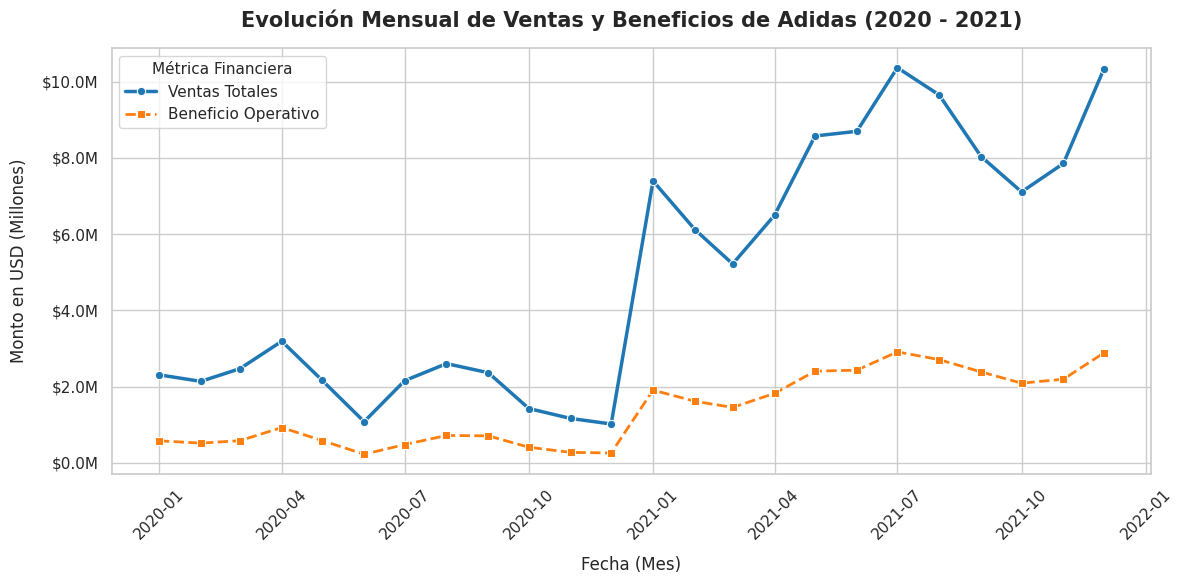

In [18]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as ticker

# Definimos la ruta del archivo y nos aseguramos de cargar los datos limpios si no están en memoria
ruta_archivo = "/content/drive/MyDrive/CURSO UTN/Adidas US Sales.csv"

try:
    # Intentamos usar la variable si ya existe en el estado actual
    df_plot = adidasdata_limpio
except NameError:
    # Si no está definida, la cargamos usando la lógica previamente aprobada
    def cargar_y_limpiar_adidas_local(path):
        df = pd.read_csv(path, dtype={'retailer_id': str})
        df['invoice_date'] = pd.to_datetime(df['invoice_date'])
        return df
    df_plot = cargar_y_limpiar_adidas_local(ruta_archivo)

# 1. Preparar los datos mensuales
# Agrupamos por mes utilizando la columna de fechas limpia
adidas_mensual = df_plot.groupby(df_plot['invoice_date'].dt.to_period('M')).agg(
    ventas_totales=('total_sales', 'sum'),
    beneficio_operativo=('operating_profit', 'sum')
).reset_index()

# Convertir el periodo a datetime para que Matplotlib lo grafique correctamente
adidas_mensual['invoice_date'] = adidas_mensual['invoice_date'].dt.to_timestamp()

# Convertir los valores a Millones de USD
adidas_mensual['ventas_millones'] = adidas_mensual['ventas_totales'] / 1e6
adidas_mensual['beneficio_millones'] = adidas_mensual['beneficio_operativo'] / 1e6

# 2. Configuración del estilo del gráfico
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(12, 6))

# Graficar Ventas Totales
sns.lineplot(
    data=adidas_mensual,
    x='invoice_date',
    y='ventas_millones',
    marker='o',
    linewidth=2.5,
    color='#1f77b4',
    label='Ventas Totales'
)

# Graficar Beneficio Operativo (sobre la misma escala de millones)
sns.lineplot(
    data=adidas_mensual,
    x='invoice_date',
    y='beneficio_millones',
    marker='s',
    linewidth=2.0,
    color='#ff7f0e',
    linestyle='--',
    label='Beneficio Operativo'
)

# 3. Personalización de etiquetas y títulos
plt.title('Evolución Mensual de Ventas y Beneficios de Adidas (2020 - 2021)', fontsize=15, fontweight='bold', pad=15)
plt.xlabel('Fecha (Mes)', fontsize=12, labelpad=10)
plt.ylabel('Monto en USD (Millones)', fontsize=12, labelpad=10)

# Dar formato de Millones al eje Y (ej: "$5.0M")
formatter = ticker.FuncFormatter(lambda x, pos: f'${x:.1f}M')
ax.yaxis.set_major_formatter(formatter)

# Configurar rotación de etiquetas de fecha para mejor lectura
plt.xticks(rotation=45)
plt.legend(title='Métrica Financiera', title_fontsize='11', loc='upper left')

plt.tight_layout()
plt.show()

### B2.KPI2

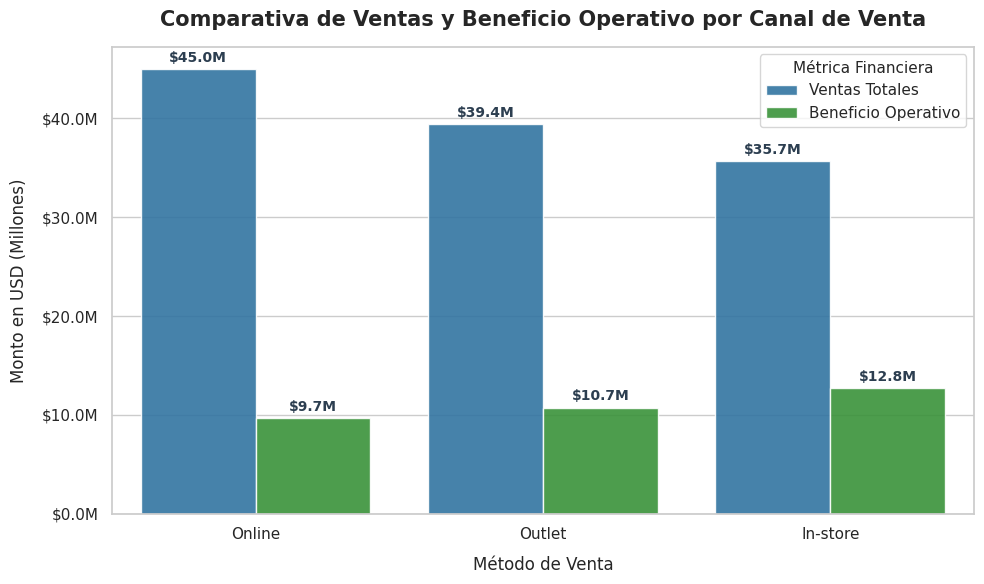

In [19]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as ticker

# 1. Asegurar la existencia y orden de los datos de canales
try:
    df_canales_group = resumen_canales.copy()
except NameError:
    df_canales_group = adidasdata_limpio.groupby('sales_method').agg(
        total_ventas=('total_sales', 'sum'),
        total_beneficio=('operating_profit', 'sum')
    ).reset_index()
    df_canales_group = df_canales_group.sort_values(by='total_ventas', ascending=False)

# Convertir métricas a millones de USD
df_canales_group['Ventas Totales'] = df_canales_group['total_ventas'] / 1e6
df_canales_group['Beneficio Operativo'] = df_canales_group['total_beneficio'] / 1e6

# Reestructurar el DataFrame para que Seaborn pueda graficar barras agrupadas (Formato Largo)
df_melted = pd.melt(
    df_canales_group,
    id_vars=['sales_method'],
    value_vars=['Ventas Totales', 'Beneficio Operativo'],
    var_name='Métrica',
    value_name='Millones_USD'
)

# 2. Configurar el gráfico
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(10, 6))

# Colores solicitados: Azul para ventas, Verde para beneficios
paleta_colores = {'Ventas Totales': '#1f77b4', 'Beneficio Operativo': '#2ca02c'}

sns.barplot(
    data=df_melted,
    x='sales_method',
    y='Millones_USD',
    hue='Métrica',
    palette=paleta_colores,
    alpha=0.9
)

# 3. Personalización del gráfico
plt.title('Comparativa de Ventas y Beneficio Operativo por Canal de Venta', fontsize=15, fontweight='bold', pad=15)
plt.xlabel('Método de Venta', fontsize=12, labelpad=10)
plt.ylabel('Monto en USD (Millones)', fontsize=12, labelpad=10)

# Formatear el eje Y a millones (ej: "$10.0M")
formatter = ticker.FuncFormatter(lambda x, pos: f'${x:.1f}M')
ax.yaxis.set_major_formatter(formatter)

# Añadir etiquetas de valor sobre cada barra
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(
            f'${height:.1f}M',
            (p.get_x() + p.get_width() / 2., height),
            ha='center',
            va='bottom',
            fontsize=10,
            fontweight='bold',
            color='#2c3e50',
            xytext=(0, 3),
            textcoords='offset points'
        )

# Ajustar leyenda y márgenes
plt.legend(title='Métrica Financiera', title_fontsize='11', loc='upper right')
plt.tight_layout()
plt.show()

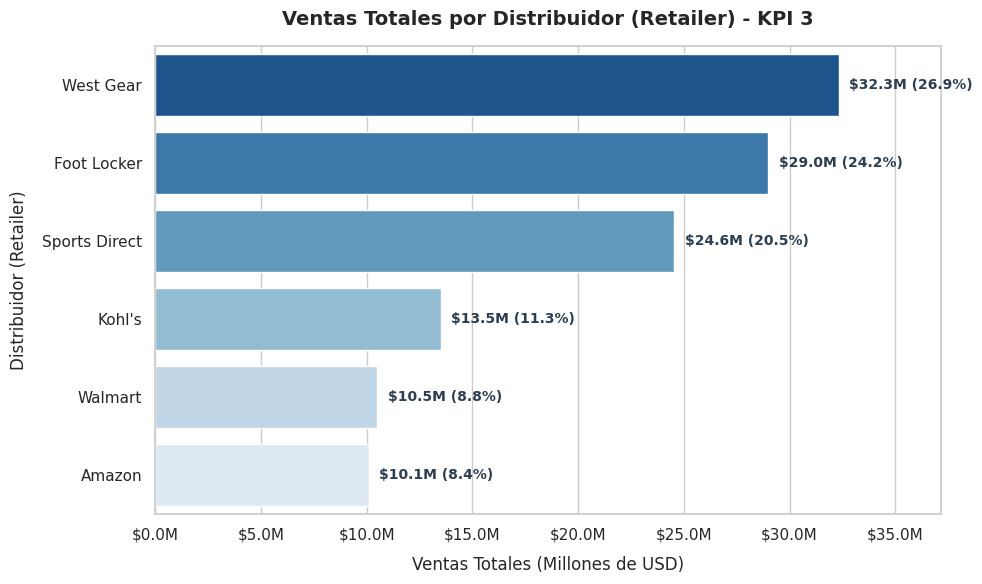

In [20]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as ticker

# 1. Asegurar la disponibilidad de los datos agregados por distribuidor
try:
    df_retailer = participacion_retailer.copy()
except NameError:
    # Recalculamos si no están definidos en memoria
    ventas_totales_global = adidasdata_limpio['total_sales'].sum()
    df_retailer = adidasdata_limpio.groupby('retailer').agg(ventas_totales=('total_sales', 'sum')).reset_index()
    df_retailer['participacion_%'] = (df_retailer['ventas_totales'] / ventas_totales_global) * 100

# Ordenar siempre de mayor a menor
df_retailer = df_retailer.sort_values(by='ventas_totales', ascending=False)

# Convertir ventas a Millones de USD para mejor lectura
df_retailer['ventas_millones'] = df_retailer['ventas_totales'] / 1e6

# 2. Configurar el estilo del gráfico
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(10, 6))

# Graficar barras horizontales
sns.barplot(
    data=df_retailer,
    x='ventas_millones',
    y='retailer',
    palette='Blues_r',  # Paleta degradada azul
    hue='retailer',
    legend=False
)

# 3. Personalización y etiquetas
plt.title('Ventas Totales por Distribuidor (Retailer) - KPI 3', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Ventas Totales (Millones de USD)', fontsize=12, labelpad=10)
plt.ylabel('Distribuidor (Retailer)', fontsize=12, labelpad=10)

# Formatear el eje X a millones de dólares (ej. "$15.0M")
ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f'${x:.1f}M'))

# Añadir etiquetas de texto al final de cada barra
for i, (idx, row) in enumerate(df_retailer.iterrows()):
    val_ventas = row['ventas_millones']
    val_part = row['participacion_%']
    ax.text(
        val_ventas + 0.5,
        i,
        f'${val_ventas:.1f}M ({val_part:.1f}%)',
        va='center',
        fontsize=10,
        fontweight='bold',
        color='#2c3e50'
    )

# Dar margen extra a la derecha para que no se corten los textos
ax.set_xlim(0, df_retailer['ventas_millones'].max() * 1.15)

plt.tight_layout()
plt.show()

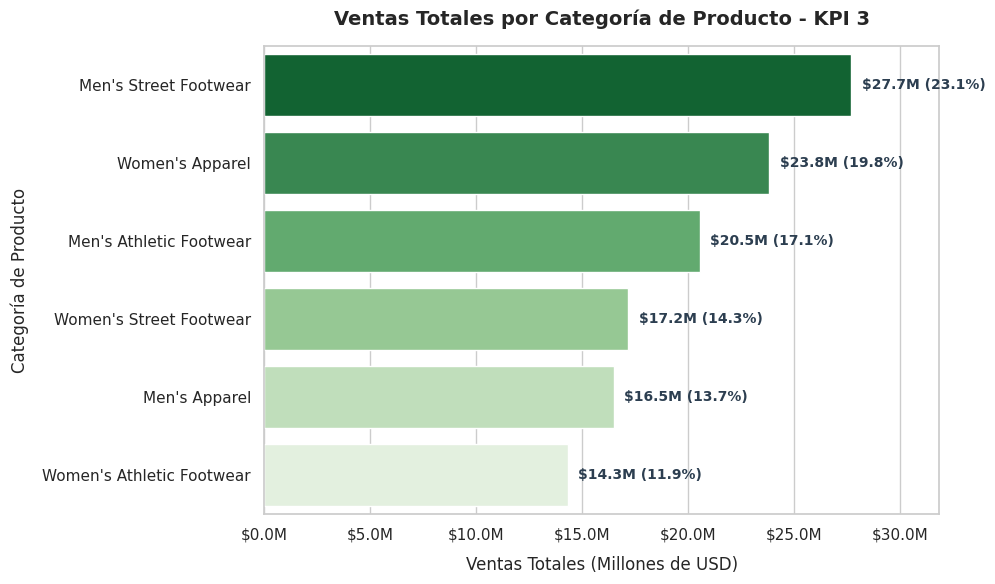

In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as ticker

# 1. Asegurar la disponibilidad de los datos agregados por producto
try:
    df_product = participacion_producto.copy()
except NameError:
    # Recalculamos si no están definidos en memoria
    ventas_totales_global = adidasdata_limpio['total_sales'].sum()
    df_product = adidasdata_limpio.groupby('product').agg(ventas_totales=('total_sales', 'sum')).reset_index()
    df_product['participacion_%'] = (df_product['ventas_totales'] / ventas_totales_global) * 100

# Ordenar de mayor a menor
df_product = df_product.sort_values(by='ventas_totales', ascending=False)

# Convertir ventas a Millones de USD
df_product['ventas_millones'] = df_product['ventas_totales'] / 1e6

# 2. Configurar el estilo del gráfico
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(10, 6))

# Graficar barras horizontales
sns.barplot(
    data=df_product,
    x='ventas_millones',
    y='product',
    palette='Greens_r',  # Paleta degradada verde
    hue='product',
    legend=False
)

# 3. Personalización y etiquetas
plt.title('Ventas Totales por Categoría de Producto - KPI 3', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Ventas Totales (Millones de USD)', fontsize=12, labelpad=10)
plt.ylabel('Categoría de Producto', fontsize=12, labelpad=10)

# Formatear el eje X a millones de dólares (ej. "$15.0M")
ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f'${x:.1f}M'))

# Añadir etiquetas de texto al final de cada barra
for i, (idx, row) in enumerate(df_product.iterrows()):
    val_ventas = row['ventas_millones']
    val_part = row['participacion_%']
    ax.text(
        val_ventas + 0.5,
        i,
        f'${val_ventas:.1f}M ({val_part:.1f}%)',
        va='center',
        fontsize=10,
        fontweight='bold',
        color='#2c3e50'
    )

# Dar margen extra a la derecha para evitar recortes de texto
ax.set_xlim(0, df_product['ventas_millones'].max() * 1.15)

plt.tight_layout()
plt.show()

In [22]:
from google.colab import files
import pandas as pd

# Definir la función de carga y limpieza
def cargar_y_limpiar_adidas(path):
    df = pd.read_csv(path, dtype={'retailer_id': str})
    df['invoice_date'] = pd.to_datetime(df['invoice_date'])
    return df

# Cargar los datos limpios en la variable
ruta_archivo = "/content/drive/MyDrive/CURSO UTN/Adidas US Sales.csv"
adidasdata_limpio = cargar_y_limpiar_adidas(ruta_archivo)

# Guardar el DataFrame como un archivo CSV local en el entorno de Colab
adidasdata_limpio.to_csv('adidas_us_sales_limpio.csv', index=False)

# Descargar el archivo CSV directamente a tu computadora
files.download('adidas_us_sales_limpio.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>